<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


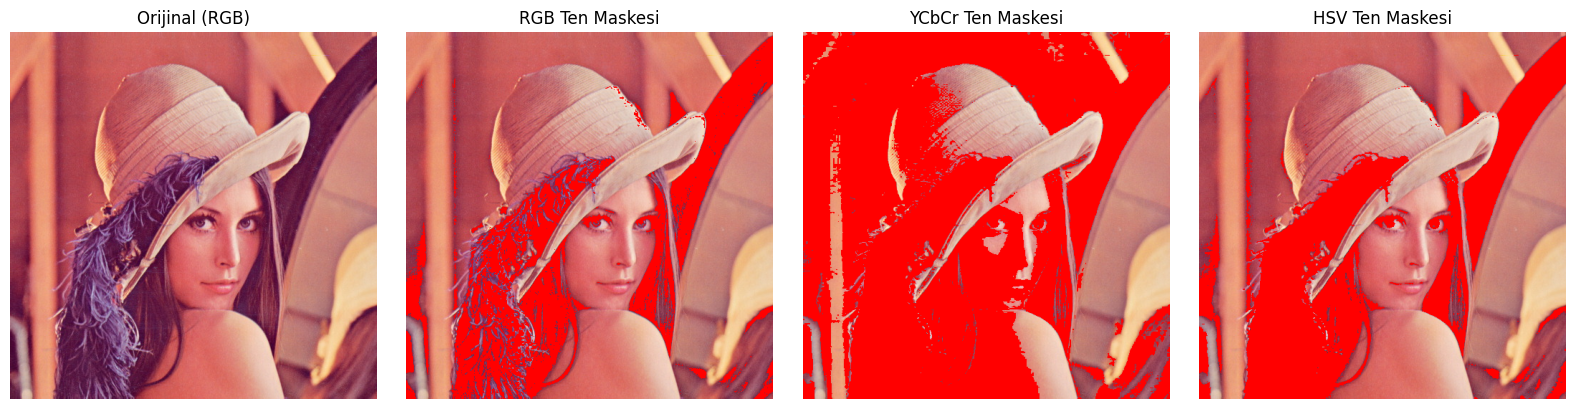

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
bgr = cv2.imdecode(arr, cv2.IMREAD_COLOR)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

R, G, B = rgb[:, :, 0].astype(np.int32), rgb[:, :, 1].astype(np.int32), rgb[:, :, 2].astype(np.int32)
skin_rgb = (
    (R > 95) & (G > 40) & (B > 20) &
    ((np.maximum(np.maximum(R, G), B) - np.minimum(np.minimum(R, G), B)) > 15) &
    (np.abs(R - G) > 15) & (R > G) & (R > B)
)
out_rgb = rgb.copy()
out_rgb[~skin_rgb] = [255, 0, 0]

ycrcb = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb)
Y, Cr, Cb = ycrcb[:, :, 0], ycrcb[:, :, 1], ycrcb[:, :, 2]
skin_ycrcb = (Y > 80) & (Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127)
out_ycrcb = rgb.copy()
out_ycrcb[~skin_ycrcb] = [255, 0, 0]

hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
skin_hsv = ((H <= 25) | (H >= 170)) & (S >= 25) & (S <= 175) & (V >= 60)
out_hsv = rgb.copy()
out_hsv[~skin_hsv] = [255, 0, 0]

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(rgb)
plt.title("Orijinal (RGB)")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(out_rgb)
plt.title("RGB Ten Maskesi")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(out_ycrcb)
plt.title("YCbCr Ten Maskesi")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(out_hsv)
plt.title("HSV Ten Maskesi")
plt.axis("off")

plt.tight_layout()
plt.show()